# Assignemnt 3: ANN analysis

## Problem statement:
Finding the stored vectors closest to a query is the core step of dense retrieval. Doing it exactly means comparing the query against every vector, which gets too slow at scale. Approximate nearest neighbour (ANN) indexes are much faster, at the price of sometimes missing a true neighbour. In this assignment you will measure that trade-off yourself. You will benchmark three popular index types, HNSW, IVF-Flat and IVF-PQ, on two public datasets, run one experiment of your choice from a short list, carry out one open-ended experiment of your own on data you generate, and write a short report explaining what you found. We care about careful measurement and clear explanations, not about which index turns out fastest.


## Index Type 2: IVF-Flat

IVF-Flat is a type of inverted file index that partitions the vector space into Voronoi cells using k-means clustering. Each cell contains a list of vectors that are closest to the corresponding centroid. When querying, the algorithm first identifies the closest centroids to the query vector and then searches only within those cells, significantly reducing the number of comparisons needed.

The logic behind IVF-Flat is that by clustering the vectors, we can limit the search space to only those vectors that are likely to be close to the query. This is particularly useful in high-dimensional spaces where the number of vectors can be very large. The trade-off is that if the query vector is not close to any of the centroids, it may miss some true nearest neighbors.

The implementation of IVF-Flat typically involves the following steps:
1. **Training**: Use k-means clustering to partition the dataset into a specified number of clusters (Voronoi cells). Each cluster is represented by its centroid.
2. **Indexing**: For each vector in the dataset, determine which centroid it is closest to and store it in the corresponding inverted list for that centroid.
3. **Querying**: Given a query vector, find the closest centroids and retrieve the vectors in their inverted lists. Then, perform a linear search within those lists to find the nearest neighbors.

## Measurement protocol (identical for all three indexes)

Part 2 of the assignment fixes how every index must be measured, so the same rules are applied here (they live in `ann_utils.py`, which the HNSW and IVF-PQ notebooks import too):

| Item | Rule used | Why |
|---|---|---|
| Quality | **recall@10**, tie-aware, against the FAISS exact reference | built and unit tested in `faiss_index_analysis.ipynb` |
| Speed | **queries per second, one query per `search()` call, one thread** | the assignment protocol; batching or threads would hide per-query cost |
| Repeats | each timing is repeated **3 times**, the **median** QPS is kept | removes one-off noise (cache state, OS jitter) |
| Sweep | the search-time parameter (`nprobe`) is increased until recall reaches about 0.99 | gives the whole recall-vs-speed curve, not a single point |
| Recall vs timing | recall is computed once on **all 10,000 queries** (one batched call, results do not depend on batching); timing uses the **first 500 queries** | keeps runtime sensible; recall stays precise |
| Baseline | exact FAISS search measured with the *same* single-query, single-thread protocol | otherwise "speedup" would compare different measurement modes |

One caveat: **building** (k-means training and adding vectors) uses all CPU threads, because single-threaded k-means on 1M vectors would take very long. Build times are therefore reported together with the thread count.

In [1]:
"""
This cell imports the shared helpers (ann_utils.py), sets the experiment configuration, loads both datasets together with their exact reference results and measures the exact-search baseline with the same single-query, single-thread protocol the indexes will be measured with. No index is built yet.
"""

import gc
import time

import faiss
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ann_utils import (K, DATASETS, MAX_THREADS, Evaluator, faiss_metric, make_flat, build_record,
                       run_sweep, set_nprobe, exact_baseline_single_thread, best_at_recall,
                       qps_table, build_table, plot_tradeoff, save_df)

# ---- experiment configuration -------------------------------------------------------------
N_TIME_Q = 500        # queries timed per repeat (the first 500 test queries)
REPS = 3              # repeats per timing; the median QPS is reported
STOP_RECALL = 0.99    # stop a sweep once recall reaches this
SEED = 1234           # k-means seed, so every run builds the same partition
NPROBE_GRID = [1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64, 96, 128, 192, 256, 384, 512, 768, 1024]

NLIST_BASE, NLIST_SMALL, NLIST_LARGE = 1024, 256, 4096    # ~ sqrt(N), 1/4 of it, 4x it

# ---- data, reference and exact baseline ---------------------------------------------------
EVAL = {name: Evaluator(name) for name in DATASETS}
BASELINE = {name: exact_baseline_single_thread(EVAL[name]) for name in DATASETS}

RESULTS, BUILDS = [], []     # every sweep point / every build is appended here

rows = []
for name, ev in EVAL.items():
    rows.append({"dataset": name, "metric": ev.metric, "N": f"{ev.n:,}", "dim": ev.d,
                 "queries": len(ev.test), "reference": ev.ref_source,
                 "exact bytes/vector": 4 * ev.d,
                 "exact QPS (1 query, 1 thread)": round(BASELINE[name]["qps"], 1)})
print(f"FAISS {faiss.__version__} | threads available for building: {MAX_THREADS} | timing: 1 thread")
print(pd.DataFrame(rows).to_string(index=False))

FAISS 1.15.1 | threads available for building: 20 | timing: 1 thread
dataset  metric         N  dim  queries                    reference  exact bytes/vector  exact QPS (1 query, 1 thread)
   sift      l2 1,000,000  128    10000 faiss exact (data/processed)                 512                           29.7
  glove angular 1,183,514  100    10000 faiss exact (data/processed)                 400                           32.6


## What IVF-Flat is made of, and what each part costs

To understand the results it helps to separate IVF-Flat into components, each with its own knob and its own cost.

| Component | Knob | What it controls | What it costs |
|---|---|---|---|
| **Coarse quantizer** (k-means centroids) | `nlist` | how finely the space is cut into cells | training time grows with `nlist x N x d x iterations`; **every query** first compares itself with all `nlist` centroids |
| **K-means quality** | `niter`, training sample, spherical or not | how well the cells follow the data, and how balanced the lists are | training time only |
| **Probing** | `nprobe` (search time) | how many of the nearest cells are scanned | scan cost grows linearly with `nprobe` |
| **List storage** | "Flat" = raw float32 vectors | distances inside a cell are **exact** | memory `N x (4d + 8)` bytes (vector + 8-byte id) |

A simple cost model for one query, assuming balanced lists, is

`work ~ nlist x d` (find nearest centroids) `+ (nprobe / nlist) x N x d` (scan the chosen lists).

This explains the central tension of the algorithm. A larger `nlist` makes each list shorter, so scanning one more cell is cheap, but the fixed centroid-scan cost grows. For `N = 1M` the two terms balance around `nlist ~ sqrt(N)`, which is where we start.

Since lists are scanned with exact distances, IVF-Flat has **no approximation error inside a cell**. It can only miss a true neighbour if that neighbour sits in a cell that was not probed. That makes IVF-Flat a clean place to learn how partitioning alone trades recall for speed.

Each experiment below (a "Try") changes **one thing** relative to the base, so any change in the curves can be attributed to that one component. Every Try has a markdown cell stating the decision, the reasoning, the alternatives that were not chosen, and a hypothesis to check against the output.

In [2]:
"""
This cell defines the two helpers used by every Try: build_ivfflat builds and times one index, and run_try_flat builds it for each dataset, records build statistics (time, size, list balance), sweeps nprobe with the single-query single-thread protocol and stores everything in RESULTS / BUILDS. The index is deleted after each dataset because an IVF-Flat index holds a full copy of the data (about 0.5 GB).
"""

def build_ivfflat(ev, nlist, niter=25, spherical=False):
    quantizer = make_flat(ev.d, ev.metric)                      # coarse quantizer = exact search over centroids
    index = faiss.IndexIVFFlat(quantizer, ev.d, nlist, faiss_metric(ev.metric))
    index.cp.niter, index.cp.seed, index.cp.spherical = niter, SEED, spherical
    t0 = time.perf_counter(); index.train(ev.train); train_s = time.perf_counter() - t0   # k-means
    t0 = time.perf_counter(); index.add(ev.train);   add_s = time.perf_counter() - t0     # assign + store
    return index, train_s, add_s


def run_try_flat(try_name, nlist, niter=25, spherical=False, datasets=None):
    print("=" * 100)
    print(try_name)
    for name in (datasets or list(DATASETS)):
        ev = EVAL[name]
        print(f"\n[{name}] building IVF-Flat: nlist={nlist}, k-means iterations={niter}, spherical={spherical}")
        index, train_s, add_s = build_ivfflat(ev, nlist, niter, spherical)
        sizes = np.array([index.invlists.list_size(i) for i in range(nlist)])
        rec = build_record(ev, index, name, "IVF-Flat", try_name,
                           f"nlist={nlist}, niter={niter}, spherical={spherical}", train_s, add_s)
        rec.update(nlist=nlist, imbalance=index.invlists.imbalance_factor(), list_min=int(sizes.min()),
                   list_mean=float(sizes.mean()), list_max=int(sizes.max()), empty_lists=int((sizes == 0).sum()))
        BUILDS.append(rec)
        print(f"[{name}] build: train {train_s:.1f} s + add {add_s:.1f} s | size {rec['size_mb']:.1f} MB "
              f"({rec['bytes_per_vector']:.0f} bytes/vector)")
        print(f"[{name}] list sizes: min {rec['list_min']}, mean {rec['list_mean']:.0f}, max {rec['list_max']}, "
              f"empty {rec['empty_lists']} | imbalance factor {rec['imbalance']:.2f} (1.0 = perfectly balanced)")

        grid = [p for p in NPROBE_GRID if p <= nlist]
        df = run_sweep(index, ev, set_nprobe, grid, n_time_q=N_TIME_Q, reps=REPS,
                       stop_recall=STOP_RECALL, param_name="nprobe", label=f"[{name}] ")
        df.insert(0, "try", try_name); df.insert(0, "dataset", name); df.insert(0, "index", "IVF-Flat")
        RESULTS.append(df)

        for t in (0.90, 0.95):
            b = best_at_recall(df, t)
            msg = (f"nprobe={int(b['param'])} (recall {b['recall']:.4f}, {b['qps']:.0f} QPS)" if b is not None
                   else f"not reached (max recall {df['recall'].max():.4f})")
            print(f"[{name}] recall >= {t}: {msg}")
        del index
        gc.collect()

print("helpers defined")

helpers defined


## Try 1: base configuration, `nlist = 1024`

**Decision.** `nlist = 1024` (about `sqrt(1M)`), default 25 k-means iterations, `nprobe` swept from 1 upwards.

**Reasoning.**
- It is the power of two closest to `sqrt(N)`, the point where the two cost terms of the model above are roughly balanced: the centroid scan (1024 comparisons) is only about 0.1% of a full scan, and a list holds about 1000 vectors.
- Training is cheap (seconds to a minute), so the base can be rebuilt quickly while we explore.
- It is the reference every other Try is compared against.

**Alternatives not chosen as the base.**
- *`nlist = 4 sqrt(N) .. 16 sqrt(N)` (4096 to 16384, the range often recommended for 1M vectors):* better for multi-threaded batch search at high recall, but its fixed per-query centroid cost is larger, and our protocol is single-query single-thread where that cost is paid in full. It is tested as Try 3 rather than assumed.
- *`nlist = 16384`:* not run at all. k-means with 16k centroids on 1M vectors takes minutes per dataset, and each list would hold only about 60 vectors, so the per-list overhead dominates. It would also complicate the `nprobe` grid (recall 0.95 would need hundreds of probes).
- *A different sweep parameter order (e.g. starting at a large `nprobe`):* the sweep goes upwards so it can stop as soon as recall reaches 0.99; there is no value in measuring slow points beyond that.

**Hypothesis.** Recall climbs steeply for the first few `nprobe` values and then flattens (diminishing returns), while QPS falls roughly in proportion to `nprobe`. Reaching 0.95 should need scanning a small percentage of the database on SIFT, and noticeably more on GloVe, which is a harder dataset for partition-based indexes.

In [3]:
"""
Try 1: nlist = 1024 (about sqrt(N)), default k-means. This is the base every other Try is compared with.
"""
run_try_flat("Try 1: nlist=1024 (base)", nlist=NLIST_BASE)

Try 1: nlist=1024 (base)

[sift] building IVF-Flat: nlist=1024, k-means iterations=25, spherical=False
[sift] build: train 12.7 s + add 1.9 s | size 520.5 MB (521 bytes/vector)
[sift] list sizes: min 339, mean 977, max 3085, empty 0 | imbalance factor 1.10 (1.0 = perfectly balanced)
  [sift] nprobe=1     recall@10=0.3746 |  18712.0 QPS (  0.053 ms/q) | compared  0.11% of db
  [sift] nprobe=2     recall@10=0.5426 |  10322.2 QPS (  0.097 ms/q) | compared  0.21% of db
  [sift] nprobe=3     recall@10=0.6409 |   7188.2 QPS (  0.139 ms/q) | compared  0.32% of db
  [sift] nprobe=4     recall@10=0.7083 |   5721.7 QPS (  0.175 ms/q) | compared  0.43% of db
  [sift] nprobe=6     recall@10=0.7923 |   3963.2 QPS (  0.252 ms/q) | compared  0.64% of db
  [sift] nprobe=8     recall@10=0.8440 |   3336.8 QPS (  0.300 ms/q) | compared  0.85% of db
  [sift] nprobe=12    recall@10=0.9027 |   2229.0 QPS (  0.449 ms/q) | compared  1.27% of db
  [sift] nprobe=16    recall@10=0.9349 |   1693.4 QPS (  0.591 ms

## Try 2: coarser partition, `nlist = 256`

**Decision.** Quarter the number of cells while changing nothing else.

**Reasoning.** This isolates the effect of cell size. Each list now holds about 4000 vectors, so every probed cell costs 4x more to scan, but the centroid scan is only 256 comparisons.

**Alternatives not chosen.** `nlist = 64` or smaller would turn IVF-Flat into little more than a handful of big buckets: the sweep would reach recall 0.95 only by scanning a large share of the database, which teaches little beyond what 256 already shows. `nlist = 512` is too close to the base to separate the effect from noise.

**Hypothesis.** Cheaper centroid step but worse recall for the same amount of work: because cells are large and irregular, a true neighbour is more likely to be separated from the query by a cell boundary, so a larger fraction of the database has to be scanned to reach 0.90 and 0.95. At the same time `nprobe = nlist` equals exact search plus overhead, so the sweep ends *slower than the exact baseline*, which is a useful sanity check of the cost model.

In [4]:
"""
Try 2: nlist = 256, everything else as the base.
"""
run_try_flat("Try 2: nlist=256 (coarser)", nlist=NLIST_SMALL)

Try 2: nlist=256 (coarser)

[sift] building IVF-Flat: nlist=256, k-means iterations=25, spherical=False
[sift] build: train 1.3 s + add 0.7 s | size 520.1 MB (520 bytes/vector)
[sift] list sizes: min 1393, mean 3906, max 9427, empty 0 | imbalance factor 1.09 (1.0 = perfectly balanced)
  [sift] nprobe=1     recall@10=0.4910 |   5966.9 QPS (  0.168 ms/q) | compared  0.43% of db
  [sift] nprobe=2     recall@10=0.6747 |   2997.7 QPS (  0.334 ms/q) | compared  0.85% of db
  [sift] nprobe=3     recall@10=0.7722 |   2085.8 QPS (  0.479 ms/q) | compared  1.26% of db
  [sift] nprobe=4     recall@10=0.8320 |   1737.0 QPS (  0.576 ms/q) | compared  1.68% of db
  [sift] nprobe=6     recall@10=0.8999 |   1117.5 QPS (  0.895 ms/q) | compared  2.50% of db
  [sift] nprobe=8     recall@10=0.9359 |    819.3 QPS (  1.221 ms/q) | compared  3.34% of db
  [sift] nprobe=12    recall@10=0.9695 |    491.8 QPS (  2.033 ms/q) | compared  4.97% of db
  [sift] nprobe=16    recall@10=0.9842 |    427.7 QPS (  2.338 

## Try 3: finer partition, `nlist = 4096`

**Decision.** Four times as many cells as the base, everything else unchanged.

**Reasoning.** This is the opposite end of the same axis. Each list holds about 250 vectors, so scanning a cell is cheap and the probed region follows the shape of the query's neighbourhood more closely. The price is a fixed cost of 4096 centroid comparisons per query, which is paid even when `nprobe = 1`.

**Alternatives not chosen.** `nlist = 16384` (see Try 1) and `nlist = 2048` (too close to 1024 or 4096 to add information).

**Hypothesis.** For the same *fraction of the database scanned* recall should be higher than with 1024 cells, because the partition is finer. Whether QPS also improves depends on whether that gain outweighs the extra centroid cost; the time split printed in the analysis cell (centroid step vs list scan) shows which term dominates. Training and adding will take noticeably longer.

In [5]:
"""
Try 3: nlist = 4096, everything else as the base.
"""
run_try_flat("Try 3: nlist=4096 (finer)", nlist=NLIST_LARGE)

Try 3: nlist=4096 (finer)

[sift] building IVF-Flat: nlist=4096, k-means iterations=25, spherical=False
[sift] build: train 185.3 s + add 7.7 s | size 522.1 MB (522 bytes/vector)
[sift] list sizes: min 68, mean 244, max 1202, empty 0 | imbalance factor 1.13 (1.0 = perfectly balanced)
  [sift] nprobe=1     recall@10=0.2871 |  16373.6 QPS (  0.061 ms/q) | compared  0.03% of db
  [sift] nprobe=2     recall@10=0.4271 |  14989.0 QPS (  0.067 ms/q) | compared  0.05% of db
  [sift] nprobe=3     recall@10=0.5171 |  12749.6 QPS (  0.078 ms/q) | compared  0.08% of db
  [sift] nprobe=4     recall@10=0.5795 |  11204.6 QPS (  0.089 ms/q) | compared  0.11% of db
  [sift] nprobe=6     recall@10=0.6677 |   8535.3 QPS (  0.117 ms/q) | compared  0.16% of db
  [sift] nprobe=8     recall@10=0.7267 |   7192.6 QPS (  0.139 ms/q) | compared  0.22% of db
  [sift] nprobe=12    recall@10=0.8013 |   5199.2 QPS (  0.192 ms/q) | compared  0.33% of db
  [sift] nprobe=16    recall@10=0.8475 |   4608.7 QPS (  0.217 m

## Try 4: under-trained k-means, 2 iterations instead of 25

**Decision.** Keep `nlist = 1024` but train the centroids for only 2 iterations (`niter = 2`).

**Reasoning.** k-means quality is a separate component from `nlist`: the number of cells is the same, only their placement differs. If centroids are poorly placed, cells follow the data badly and some become very large while others stay small (high *imbalance factor*), which hurts both recall per probe and scan cost.

**Alternatives not chosen.**
- *`niter = 1` or random centroids:* too extreme to be informative, it only shows that no training is bad.
- *`niter = 100`:* the default of 25 is already close to convergence, so more iterations cost 4x the training time for a tiny change. It would only be worth testing if Try 1 showed signs of unconverged cells.
- *Changing the training sample size:* FAISS already caps the sample at 256 points per centroid (262k points for 1024 centroids), which is plenty; varying it would mix two effects.

**Hypothesis.** The imbalance factor rises, and recall at a given `nprobe` drops somewhat. The effect may be smaller than expected on SIFT, because even rough cells are reasonably useful; the instructive part is how little or how much k-means quality matters compared with `nlist`.

In [6]:
"""
Try 4: nlist = 1024 but only 2 k-means iterations (poor centroids).
"""
run_try_flat("Try 4: nlist=1024, niter=2 (under-trained)", nlist=NLIST_BASE, niter=2)

Try 4: nlist=1024, niter=2 (under-trained)

[sift] building IVF-Flat: nlist=1024, k-means iterations=2, spherical=False
[sift] build: train 1.5 s + add 2.0 s | size 520.5 MB (521 bytes/vector)
[sift] list sizes: min 85, mean 977, max 4303, empty 0 | imbalance factor 1.24 (1.0 = perfectly balanced)
  [sift] nprobe=1     recall@10=0.3599 |  16435.9 QPS (  0.061 ms/q) | compared  0.12% of db
  [sift] nprobe=2     recall@10=0.5201 |   9377.6 QPS (  0.107 ms/q) | compared  0.24% of db
  [sift] nprobe=3     recall@10=0.6189 |   7203.3 QPS (  0.139 ms/q) | compared  0.35% of db
  [sift] nprobe=4     recall@10=0.6862 |   5333.5 QPS (  0.187 ms/q) | compared  0.47% of db
  [sift] nprobe=6     recall@10=0.7740 |   3310.0 QPS (  0.302 ms/q) | compared  0.69% of db
  [sift] nprobe=8     recall@10=0.8276 |   2599.7 QPS (  0.385 ms/q) | compared  0.91% of db
  [sift] nprobe=12    recall@10=0.8915 |   2021.1 QPS (  0.495 ms/q) | compared  1.35% of db
  [sift] nprobe=16    recall@10=0.9258 |   1419.2 

## Try 5: spherical k-means (GloVe only)

**Decision.** For the angular dataset, repeat the base with `spherical = True`, which re-normalises each centroid to unit length after every k-means step. Run on GloVe only, because SIFT uses L2 distance where this option makes no sense.

**Reasoning.** GloVe is searched by inner product on unit vectors. The ordinary k-means centroid is the *mean* of its cluster, whose length is below 1 and shorter for diffuse clusters. When a query is matched to centroids by inner product, those length differences bias the choice towards tight clusters instead of towards the true direction. Spherical k-means removes the bias by clustering directions, which is what cosine similarity actually compares.

**Alternatives not chosen.**
- *Normalising centroids only at query time:* the cells would still have been built with the biased procedure.
- *Using L2 on normalised vectors:* equivalent ranking to inner product, but it would give up the direct match with the dataset's angular metric used everywhere else.

**Hypothesis.** More balanced lists (lower imbalance factor) and better recall at a given `nprobe` than the base on GloVe. If the difference is small, that is also a result worth reporting. Whether to use it in later Tries is a decision for the improvement part of the assignment.

In [7]:
"""
Try 5: spherical k-means on the angular dataset only (nlist = 1024).
"""
run_try_flat("Try 5: nlist=1024, spherical k-means (GloVe)", nlist=NLIST_BASE, spherical=True, datasets=["glove"])

Try 5: nlist=1024, spherical k-means (GloVe)

[glove] building IVF-Flat: nlist=1024, k-means iterations=25, spherical=True
[glove] build: train 8.8 s + add 1.8 s | size 483.3 MB (408 bytes/vector)
[glove] list sizes: min 174, mean 1156, max 3380, empty 0 | imbalance factor 1.18 (1.0 = perfectly balanced)
  [glove] nprobe=1     recall@10=0.4083 |  13134.1 QPS (  0.076 ms/q) | compared  0.12% of db
  [glove] nprobe=2     recall@10=0.5420 |   9938.7 QPS (  0.101 ms/q) | compared  0.23% of db
  [glove] nprobe=3     recall@10=0.6130 |   7224.1 QPS (  0.138 ms/q) | compared  0.34% of db
  [glove] nprobe=4     recall@10=0.6590 |   5772.2 QPS (  0.173 ms/q) | compared  0.46% of db
  [glove] nprobe=6     recall@10=0.7156 |   4238.2 QPS (  0.236 ms/q) | compared  0.68% of db
  [glove] nprobe=8     recall@10=0.7527 |   3259.8 QPS (  0.307 ms/q) | compared  0.90% of db
  [glove] nprobe=12    recall@10=0.7986 |   2179.6 QPS (  0.459 ms/q) | compared  1.34% of db
  [glove] nprobe=16    recall@10=0.8

## Comparing the Tries: which component bought what?

The table below puts the Tries side by side for each dataset. For each recall target it shows the **fastest measured configuration that reaches it**, the `nprobe` it needed, the **percentage of the database whose vectors were actually compared** and the resulting QPS. The second table splits the per-query time at recall 0.95 into the **centroid step** (finding the nearest cells) and the **list scan**, which makes the `nlist` trade-off visible directly.

How to read it:
- *Same scan percentage, different recall* means the partition quality differs (Tries 1 vs 2 vs 3, Try 4, Try 5).
- *Same recall, different QPS* means the fixed centroid cost or list layout differs.
- The imbalance factor shows how uneven the cells are (it is 1.0 when all lists are equal).

In [8]:
"""
This cell compares all Tries: recall targets 0.90 and 0.95, nprobe needed, share of the database compared, QPS, list balance and the split of query time between the centroid step and the list scan.
"""
RES = pd.concat(RESULTS, ignore_index=True)
BLD = pd.DataFrame(BUILDS)

for ds in DATASETS:
    n = EVAL[ds].n
    rows, split = [], []
    for tr, g in RES[RES["dataset"] == ds].groupby("try", sort=False):
        b = BLD[(BLD["dataset"] == ds) & (BLD["try"] == tr)].iloc[0]
        row = {"try": tr, "imbalance": round(b["imbalance"], 2), "max recall": round(g["recall"].max(), 4)}
        for t in (0.90, 0.95):
            r = best_at_recall(g, t)
            row[f"nprobe@{t}"] = int(r["param"]) if r is not None else None
            row[f"scanned%@{t}"] = round(r["dist_comps_per_query"] / n * 100, 2) if r is not None else None
            row[f"QPS@{t}"] = round(r["qps"], 1) if r is not None else None
        rows.append(row)
        r95 = best_at_recall(g, 0.95)
        if r95 is not None:
            split.append({"try": tr, "nlist": int(b["nlist"]), "centroid comps/query": int(b["nlist"]),
                          "list comps/query": int(r95["dist_comps_per_query"]),
                          "centroid step ms": round(r95["quantize_ms_per_query"], 3),
                          "list scan ms": round(r95["scan_ms_per_query"], 3),
                          "total ms (measured)": round(r95["ms_per_query"], 3)})
    print(f"\n===== {ds}: Tries side by side (exact baseline: {BASELINE[ds]['qps']:.1f} QPS) =====")
    print(pd.DataFrame(rows).to_string(index=False))
    print(f"\n----- {ds}: where the time goes at recall >= 0.95 -----")
    print(pd.DataFrame(split).to_string(index=False))

print("\n===== build cost =====")
print(BLD[["dataset", "try", "train_s", "add_s", "size_mb", "bytes_per_vector"]].round(1).to_string(index=False))


===== sift: Tries side by side (exact baseline: 29.7 QPS) =====
                                       try  imbalance  max recall  nprobe@0.9  scanned%@0.9  QPS@0.9  nprobe@0.95  scanned%@0.95  QPS@0.95
                  Try 1: nlist=1024 (base)       1.10      0.9924          12          1.27   2229.0           24           2.51    1064.5
                Try 2: nlist=256 (coarser)       1.09      0.9947           8          3.34    819.3           12           4.97     491.8
                 Try 3: nlist=4096 (finer)       1.13      0.9945          24          0.65   3406.0           48           1.28    1779.6
Try 4: nlist=1024, niter=2 (under-trained)       1.24      0.9904          16          1.77   1419.2           24           2.62     994.5

----- sift: where the time goes at recall >= 0.95 -----
                                       try  nlist  centroid comps/query  list comps/query  centroid step ms  list scan ms  total ms (measured)
                  Try 1: nlist=1024 (bas

## Report item 1: recall@10 against queries per second

Each thin line is one build setting; the **bold black line is the best trade-off curve** (a configuration is on it only if no other measured configuration is both faster and at least as accurate). The red star is exact FAISS search measured with the same single-query, single-thread protocol. Dotted vertical lines mark recall 0.90 and 0.95. Because only the best curve is asked for in the final report, the thin lines are what show *why* a setting is or is not on it.

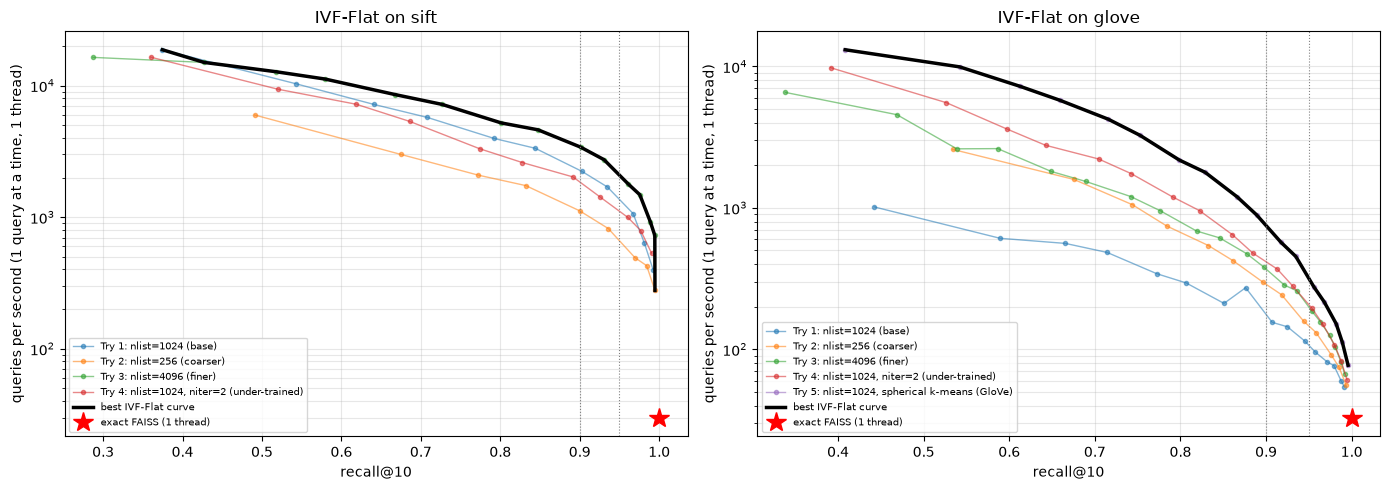

In [9]:
"""
This cell plots recall@10 against QPS (log scale) for each dataset, with every build setting as a thin line, the best trade-off curve in bold and the exact baseline as a star. The figure is also saved to data/processed/plots.
"""
fig = plot_tradeoff(RES, BASELINE, "IVF-Flat", "./data/processed/plots/ivfflat_tradeoff.png")
plt.show()

## Report items 2 and 3: tables at recall 0.90 and 0.95

The first table gives the fastest measured configuration (over all Tries) that reaches each recall target, with the actual recall it achieved, which Try it came from and the `nprobe` used. The second table gives build time, index size and bytes per vector for the configuration that reaches recall 0.95. For comparison, exact search stores `4 x d` bytes per vector (512 for SIFT, 400 for GloVe) and needs no build.

Note that bytes per vector includes everything in the index file: the stored vector, its 8-byte id and the (small) share of the centroids.

In [10]:
"""
This cell prints the two report tables: QPS at recall 0.90 and 0.95, and build time / index size / bytes per vector for the configuration that reaches recall 0.95.
"""
print("QPS at recall 0.90 and 0.95 (best configuration over all Tries; one query at a time, one thread)")
print(qps_table(RES).to_string(index=False))
print("\nexact FAISS baseline QPS:", {k: round(v["qps"], 1) for k, v in BASELINE.items()})

print(f"\nBuild time, index size and bytes per vector at recall 0.95 (build threads: {MAX_THREADS})")
print(build_table(RES, BLD).to_string(index=False))
print("\nexact search for comparison: bytes per vector =", {k: 4 * EVAL[k].d for k in DATASETS}, "(no build step)")

QPS at recall 0.90 and 0.95 (best configuration over all Tries; one query at a time, one thread)
dataset  target_recall    qps  recall                                      setting  param
  glove           0.90  571.4  0.9173 Try 5: nlist=1024, spherical k-means (GloVe)     48
  glove           0.95  276.9  0.9557 Try 5: nlist=1024, spherical k-means (GloVe)     96
   sift           0.90 3406.0  0.9010                    Try 3: nlist=4096 (finer)     24
   sift           0.95 1779.6  0.9613                    Try 3: nlist=4096 (finer)     48

exact FAISS baseline QPS: {'sift': 29.7, 'glove': 32.6}

Build time, index size and bytes per vector at recall 0.95 (build threads: 20)
dataset                                      setting                                 build  param  recall  build_s  size_mb  bytes_per_vector
  glove Try 5: nlist=1024, spherical k-means (GloVe)  nlist=1024, niter=25, spherical=True     96  0.9557     10.6    483.3             408.4
   sift                    Try 3

## Why an index might fail to reach high recall: the IVF-Flat case

IVF-Flat compares the query with the **exact vectors** inside the probed cells, so it cannot make distance errors. The only way it can miss a true neighbour is **a cell that was never probed**: the neighbour lies just across a cell boundary, and the query's `nprobe` nearest centroids do not include that cell. Recall therefore rises monotonically with `nprobe`, and reaches 1.0 when `nprobe = nlist`, at which point the search is exhaustive and, because of the centroid overhead, slower than the exact baseline.

So for IVF-Flat the answer to "why does it fail to reach 0.95?" is purely about **probing budget**: if a setting does not reach 0.95 within our sweep, it is because the cost of probing enough cells was not worth it (the sweep stopped at 0.99, or at `nprobe = nlist`), not because the index is unable to represent the data. This contrasts with IVF-PQ, where compression adds a second, independent source of missed neighbours that more probing cannot fix.

The cell below prints the highest recall each Try reached, as a check of this statement.

In [11]:
"""
This cell prints the highest recall reached by each Try and the nprobe at which the sweep ended, to check whether any setting fails to reach 0.95.
"""
for ds in DATASETS:
    print(f"[{ds}]")
    for tr, g in RES[RES["dataset"] == ds].groupby("try", sort=False):
        last = g.iloc[-1]
        print(f"  {tr:<46} max recall@10 = {g['recall'].max():.4f} (sweep ended at nprobe={int(last['param'])}) "
              f"-> reaches 0.95: {'yes' if g['recall'].max() >= 0.95 else 'NO'}")

[sift]
  Try 1: nlist=1024 (base)                       max recall@10 = 0.9923 (sweep ended at nprobe=48) -> reaches 0.95: yes
  Try 2: nlist=256 (coarser)                     max recall@10 = 0.9947 (sweep ended at nprobe=24) -> reaches 0.95: yes
  Try 3: nlist=4096 (finer)                      max recall@10 = 0.9945 (sweep ended at nprobe=128) -> reaches 0.95: yes
  Try 4: nlist=1024, niter=2 (under-trained)     max recall@10 = 0.9904 (sweep ended at nprobe=48) -> reaches 0.95: yes
[glove]
  Try 1: nlist=1024 (base)                       max recall@10 = 0.9915 (sweep ended at nprobe=256) -> reaches 0.95: yes
  Try 2: nlist=256 (coarser)                     max recall@10 = 0.9936 (sweep ended at nprobe=96) -> reaches 0.95: yes
  Try 3: nlist=4096 (finer)                      max recall@10 = 0.9917 (sweep ended at nprobe=1024) -> reaches 0.95: yes
  Try 4: nlist=1024, niter=2 (under-trained)     max recall@10 = 0.9947 (sweep ended at nprobe=384) -> reaches 0.95: yes
  Try 5: nlist=1024,

## Saving the results

The sweep points and build records are saved so the final comparison across HNSW, IVF-Flat and IVF-PQ (and the tweak experiments) can be produced without re-running anything.

In [12]:
"""
This cell saves all sweep points and build records of this notebook as csv files in data/processed.
"""
print("saved:", save_df(RES, "results_ivfflat.csv"))
print("saved:", save_df(BLD, "builds_ivfflat.csv"))
print(f"{len(RES)} sweep points over {RES['try'].nunique()} Tries, {len(BLD)} index builds")

saved: ./data/processed/results_ivfflat.csv
saved: ./data/processed/builds_ivfflat.csv
128 sweep points over 5 Tries, 9 index builds


## Observations (fill in after running)

Use these prompts to turn the output above into the explanations the report asks for.

- **Effect of `nlist`** (Tries 1 to 3): which value gave the best QPS at recall 0.95 on each dataset? How does the share of the database that has to be scanned change with `nlist`? How much of the per-query time is the centroid step for `nlist = 4096`?
- **Effect of k-means quality** (Try 4): how different are the imbalance factor and the recall at equal `nprobe` from the base?
- **Angular data** (Try 5): did spherical k-means improve balance and recall on GloVe?
- **SIFT vs GloVe**: which dataset needs more probing for the same recall, and what does that say about how well the data splits into cells?
- **Against exact search**: at which recall does IVF-Flat stop being faster than the exact baseline?
- **Cost of the speedup**: compare bytes per vector with the 512 (SIFT) and 400 (GloVe) bytes of exact search; IVF-Flat gives no memory saving, which is the gap IVF-PQ is designed to close.